# Proyecto final — Visión por Computador I

**Objetivo:** identificar y segmentar las manzanas del árbol utilizando únicamente técnicas tradicionales estudiadas en la asignatura.

El notebook sigue un único recorrido:

1. Configuración y datos.
2. Métricas de evaluación.
3. Preprocesado y operaciones morfológicas.
4. Análisis de color.
5. Segmentación por color y umbrales.
6. GMM.
7. Canny y Hough.
8. Watershed.
9. LBP y HOG.
10. Comparación de métodos.
11. Selección con ajuste.
12. Evaluación final con test.
13. Visualización y conclusiones.

Se mantiene la separación **70 % ajuste / 30 % test**. El conjunto de test solo se utiliza al final.

In [1]:
import os
import random
from pathlib import Path

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass

try:
    from sklearn.mixture import GaussianMixture
except ImportError:
    raise ImportError("Este notebook necesita scikit-learn para el método GMM.")

## 1. Configuración y carga de datos

Las imágenes y sus máscaras de referencia deben estar en:

- `dataset_manzanas/imagenes`
- `dataset_manzanas/mascaras`

Las máscaras tienen el mismo nombre que las imágenes.

In [2]:
CARPETA = r"./dataset_manzanas"
SUBCARPETA_IMAGENES = "imagenes"
SUBCARPETA_MASCARAS = "mascaras"

SEMILLA = 42
FRAC_AJUSTE = 0.70

nombres = sorted(os.listdir(os.path.join(CARPETA, SUBCARPETA_IMAGENES)))

random.seed(SEMILLA)
random.shuffle(nombres)

corte = int(len(nombres) * FRAC_AJUSTE)
ajuste = nombres[:corte]
test = nombres[corte:]

def cargar_par(nombre):
    img = cv.imread(os.path.join(CARPETA, SUBCARPETA_IMAGENES, nombre))
    mascara = cv.imread(
        os.path.join(CARPETA, SUBCARPETA_MASCARAS, nombre),
        cv.IMREAD_GRAYSCALE
    )
    if img is None or mascara is None:
        raise FileNotFoundError(f"No se pudo cargar {nombre}")
    return img, (mascara > 127).astype(np.uint8)

print(f"Imágenes totales: {len(nombres)}")
print(f"Ajuste: {len(ajuste)}")
print(f"Test: {len(test)}")

Imágenes totales: 100
Ajuste: 70
Test: 30


## 2. Métricas

Se utilizan métricas a nivel de píxel y a nivel de objeto.

A nivel de píxel se calculan exactitud, precisión, recall, IoU y Dice.

A nivel de objeto se calculan TP, FP, FN, precisión, recall y F1 mediante IoU real y emparejamiento 1 a 1.

In [3]:
def _div(a, b):
    return a / b if b > 0 else 0.0

def metricas_pixel(pred, gt):
    p = pred > 0
    g = gt > 0

    TP = int(np.sum(p & g))
    TN = int(np.sum(~p & ~g))
    FP = int(np.sum(p & ~g))
    FN = int(np.sum(~p & g))

    return {
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "exactitud": _div(TP + TN, p.size),
        "precision": _div(TP, TP + FP),
        "recall": _div(TP, TP + FN),
        "iou": _div(TP, TP + FP + FN),
        "dice": _div(2 * TP, 2 * TP + FP + FN)
    }

def _componentes_validos(binary, area_min=30):
    binary = (binary > 0).astype(np.uint8)
    n, labels, stats, _ = cv.connectedComponentsWithStats(binary, connectivity=8)

    areas = stats[:, cv.CC_STAT_AREA]
    ids = np.where(areas >= area_min)[0]
    ids = ids[ids != 0]

    return labels, ids, areas

def metricas_objeto(pred, gt, iou_min=0.5, area_min=30):
    lp, ids_p, areas_p = _componentes_validos(pred, area_min)
    lg, ids_g, areas_g = _componentes_validos(gt, area_min)

    n_pred = len(ids_p)
    n_gt = len(ids_g)

    TP = 0

    if n_pred > 0 and n_gt > 0:
        mapa_p = np.zeros(int(lp.max()) + 1, dtype=np.int32)
        mapa_g = np.zeros(int(lg.max()) + 1, dtype=np.int32)

        mapa_p[ids_p] = np.arange(1, n_pred + 1)
        mapa_g[ids_g] = np.arange(1, n_gt + 1)

        p = mapa_p[lp]
        g = mapa_g[lg]

        validos = (p > 0) & (g > 0)
        codigos = p[validos] * (n_gt + 1) + g[validos]

        inter = np.bincount(
            codigos,
            minlength=(n_pred + 1) * (n_gt + 1)
        ).reshape(n_pred + 1, n_gt + 1)[1:, 1:]

        ap = areas_p[ids_p]
        ag = areas_g[ids_g]

        union = ap[:, None] + ag[None, :] - inter
        ious = np.divide(
            inter,
            union,
            out=np.zeros_like(inter, dtype=float),
            where=union > 0
        )

        pares = np.argwhere(ious >= iou_min)
        pares = sorted(
            pares,
            key=lambda x: ious[x[0], x[1]],
            reverse=True
        )

        usados_p = set()
        usados_g = set()

        for i, j in pares:
            if i not in usados_p and j not in usados_g:
                usados_p.add(i)
                usados_g.add(j)
                TP += 1

    FP = n_pred - TP
    FN = n_gt - TP

    precision = _div(TP, TP + FP)
    recall = _div(TP, TP + FN)
    f1 = _div(2 * precision * recall, precision + recall)

    return {
        "obj_TP": TP,
        "obj_FP": FP,
        "obj_FN": FN,
        "obj_precision": precision,
        "obj_recall": recall,
        "obj_f1": f1,
        "n_gt": n_gt,
        "n_pred": n_pred,
        "error_conteo": n_pred - n_gt
    }

def metricas_completas(pred, gt):
    fila = metricas_pixel(pred, gt)
    fila.update(metricas_objeto(pred, gt))
    fila["error_abs"] = abs(fila["error_conteo"])
    return fila

## 3. Preprocesado, segmentación y postprocesado

Se define una estructura común para todos los métodos:

**preprocesado → segmentación → postprocesado**

Así todos los métodos se pueden comparar con el mismo procedimiento.

In [4]:
def mediana(img, k=5):
    return cv.medianBlur(img, k)

def gauss(img, k=5, sigma=1.5):
    return cv.GaussianBlur(img, (k, k), sigma)

def clahe_l(img, clip=2.0, tile=8):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    clahe = cv.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv.cvtColor(lab, cv.COLOR_LAB2BGR)

def umbral_hsv(img, h=(22, 40), s=(70, 255), v=(90, 255)):
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    return cv.inRange(
        hsv,
        (h[0], s[0], v[0]),
        (h[1], s[1], v[1])
    )

def umbral_b(img, lo=185, hi=255):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    return cv.inRange(lab[:, :, 2], lo, hi)

def umbral_bL(img, b_lo=185, L_lo=0):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    return (
        (lab[:, :, 2] >= b_lo) &
        (lab[:, :, 0] >= L_lo)
    ).astype(np.uint8) * 255

def otsu_b(img):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    _, mascara = cv.threshold(
        lab[:, :, 2], 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )
    return mascara

def otsu_gris(img):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    _, mascara = cv.threshold(
        gris, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )
    return mascara

def adaptativo_b(img, bloque=51, c=10, minimo=150):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    b = lab[:, :, 2]
    local = cv.adaptiveThreshold(
        b, 255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        bloque,
        c
    )
    return cv.bitwise_and(local, (b >= minimo).astype(np.uint8) * 255)

def abrir_cerrar(mascara, img, k_abrir=3, k_cerrar=5):
    m = (mascara > 0).astype(np.uint8) * 255
    k1 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_abrir, k_abrir))
    k2 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_cerrar, k_cerrar))
    m = cv.morphologyEx(m, cv.MORPH_OPEN, k1)
    m = cv.morphologyEx(m, cv.MORPH_CLOSE, k2)
    return m

def filtrar_area(mascara, img, area_min=40, area_max=None):
    m = (mascara > 0).astype(np.uint8)
    n, etiquetas, stats, _ = cv.connectedComponentsWithStats(m, connectivity=8)
    salida = np.zeros_like(m)

    for i in range(1, n):
        area = stats[i, cv.CC_STAT_AREA]
        if area >= area_min and (area_max is None or area <= area_max):
            salida[etiquetas == i] = 255

    return salida

def rellenar_huecos(mascara, img):
    m = (mascara > 0).astype(np.uint8)
    fondo = 1 - m

    _, etiquetas = cv.connectedComponents(fondo, connectivity=4)

    borde = np.unique(np.concatenate([
        etiquetas[0, :],
        etiquetas[-1, :],
        etiquetas[:, 0],
        etiquetas[:, -1]
    ]))

    huecos = (fondo == 1) & (~np.isin(etiquetas, borde))
    return ((m == 1) | huecos).astype(np.uint8) * 255

def dilatar(mascara, img, k=5):
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k))
    return cv.dilate(
        (mascara > 0).astype(np.uint8) * 255,
        kernel
    )

def histeresis_b(img, alto=185, bajo=175):
    b = cv.cvtColor(img, cv.COLOR_BGR2LAB)[:, :, 2]

    fuerte = b >= alto
    debil = (b >= bajo).astype(np.uint8)

    _, etiquetas = cv.connectedComponents(debil, connectivity=8)
    con_semilla = np.unique(etiquetas[fuerte])
    con_semilla = con_semilla[con_semilla > 0]

    return np.isin(etiquetas, con_semilla).astype(np.uint8) * 255

In [5]:
CATALOGO = {
    "mediana": mediana,
    "gauss": gauss,
    "clahe_l": clahe_l,
    "umbral_hsv": umbral_hsv,
    "umbral_b": umbral_b,
    "umbral_bL": umbral_bL,
    "otsu_b": otsu_b,
    "otsu_gris": otsu_gris,
    "adaptativo_b": adaptativo_b,
    "abrir_cerrar": abrir_cerrar,
    "filtrar_area": filtrar_area,
    "rellenar_huecos": rellenar_huecos,
    "dilatar": dilatar,
    "histeresis_b": histeresis_b,
}

class Metodo:
    def __init__(self, nombre, seg, preproc=None, post=None):
        self.nombre = nombre
        self.seg = seg
        self.preproc = preproc or []
        self.post = post or []

    def __call__(self, img):
        x = img

        for nombre, params in self.preproc:
            x = CATALOGO[nombre](x, **params)

        nombre, params = self.seg
        mascara = CATALOGO[nombre](x, **params)

        for nombre, params in self.post:
            mascara = CATALOGO[nombre](mascara, img, **params)

        return (mascara > 0).astype(np.uint8)

def evaluar(metodo, nombres, mostrar_progreso=True):
    filas = []

    for i, nombre in enumerate(nombres, start=1):
        img, gt = cargar_par(nombre)
        pred = metodo(img)

        fila = {"metodo": metodo.nombre, "id": nombre}
        fila.update(metricas_completas(pred, gt))
        filas.append(fila)

        if mostrar_progreso and (i == 1 or i % 10 == 0 or i == len(nombres)):
            print(f"{metodo.nombre}: {i}/{len(nombres)}")

    return pd.DataFrame(filas)

def comparar(metodos, nombres):
    tablas = []
    for metodo in metodos:
        tablas.append(evaluar(metodo, nombres))
    return pd.concat(tablas, ignore_index=True)

def resumen(tabla):
    columnas = [
        "iou", "dice", "precision", "recall",
        "obj_f1", "obj_precision", "obj_recall",
        "error_conteo", "error_abs"
    ]

    return (
        tabla.groupby("metodo")[columnas]
        .mean()
        .sort_values(["dice", "obj_f1"], ascending=False)
    )

def mostrar(img, pred, gt, titulo=""):
    errores = np.zeros((*gt.shape, 3), dtype=np.uint8)
    errores[(pred > 0) & (gt > 0)] = (0, 255, 0)
    errores[(pred > 0) & (gt == 0)] = (255, 0, 0)
    errores[(pred == 0) & (gt > 0)] = (0, 0, 255)

    fig, ax = plt.subplots(1, 4, figsize=(17, 6))

    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")

    ax[1].imshow(gt, cmap="gray")
    ax[1].set_title("Máscara real")

    ax[2].imshow(pred, cmap="gray")
    ax[2].set_title("Predicción")

    ax[3].imshow(errores)
    ax[3].set_title("Verde=TP | Rojo=FP | Azul=FN")

    for a in ax:
        a.axis("off")

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## 4. Análisis de color

Antes de elegir los umbrales se comparan los canales HSV y Lab entre manzana y fondo.

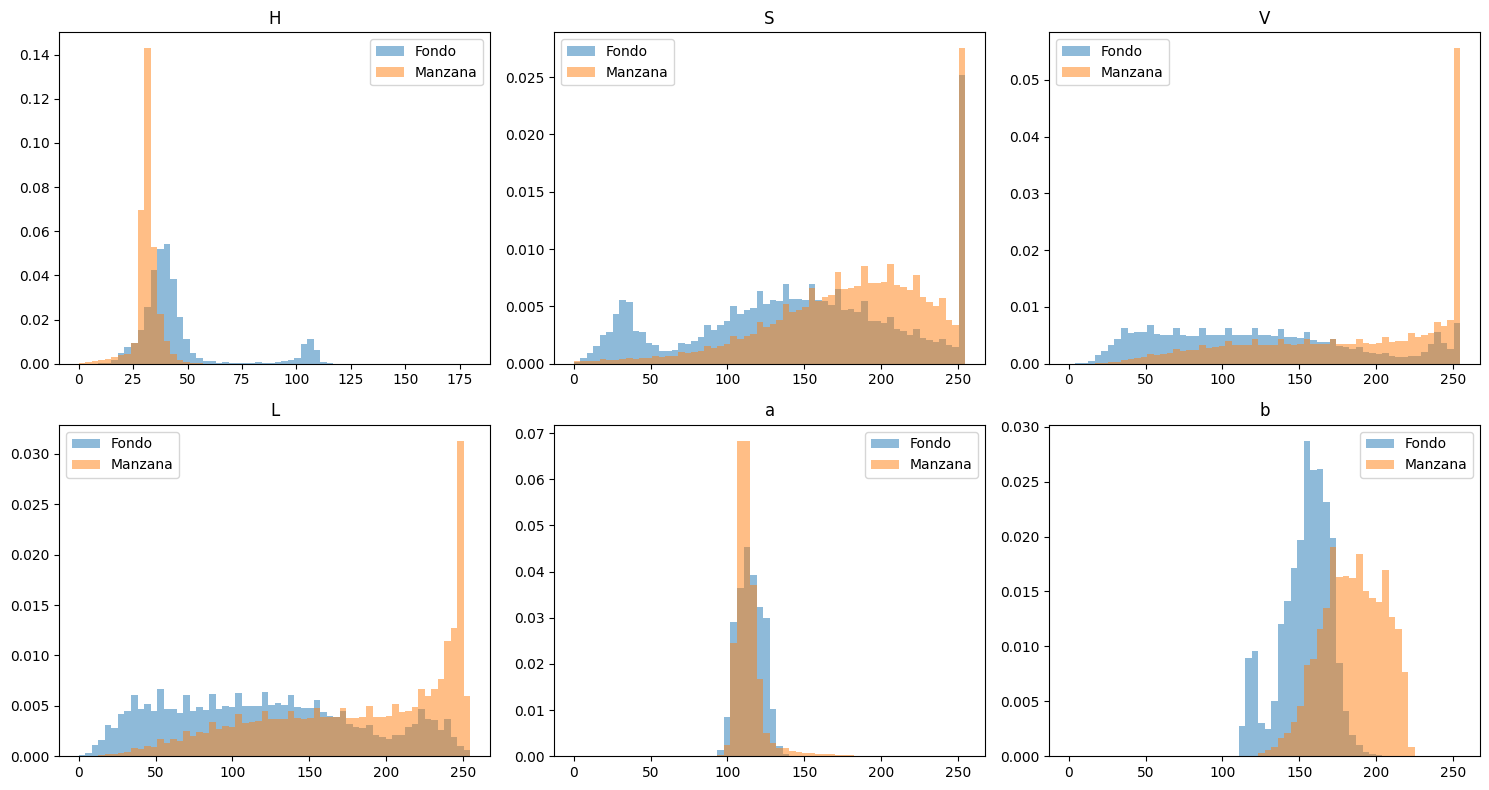

H: manzana 31.1 ± 7.2 | fondo 44.7 ± 21.9
S: manzana 183.5 ± 52.7 | fondo 146.8 ± 68.3
V: manzana 185.3 ± 64.6 | fondo 122.5 ± 64.6
L: manzana 180.3 ± 61.5 | fondo 120.2 ± 63.0
a: manzana 113.5 ± 9.4 | fondo 114.8 ± 8.2
b: manzana 184.8 ± 19.9 | fondo 153.8 ± 16.7


In [6]:
manzana = []
fondo = []

for nombre in ajuste:
    img, gt = cargar_par(nombre)

    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    pixeles = np.dstack([hsv, lab]).reshape(-1, 6)

    etiqueta = gt.reshape(-1)

    manzana.append(pixeles[etiqueta == 1][::5])
    fondo.append(pixeles[etiqueta == 0][::50])

manzana = np.vstack(manzana)
fondo = np.vstack(fondo)

canales = ["H", "S", "V", "L", "a", "b"]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()

for i, canal in enumerate(canales):
    rango = (0, 180) if canal == "H" else (0, 255)

    ax[i].hist(
        fondo[:, i], bins=60, range=rango,
        density=True, alpha=0.5, label="Fondo"
    )
    ax[i].hist(
        manzana[:, i], bins=60, range=rango,
        density=True, alpha=0.5, label="Manzana"
    )

    ax[i].set_title(canal)
    ax[i].legend()

plt.tight_layout()
plt.show()

for i, canal in enumerate(canales):
    print(
        f"{canal}: "
        f"manzana {manzana[:, i].mean():.1f} ± {manzana[:, i].std():.1f} | "
        f"fondo {fondo[:, i].mean():.1f} ± {fondo[:, i].std():.1f}"
    )

## 5. Búsqueda de umbrales de color

Se busca un rango de cada canal que maximice el Dice sobre los píxeles de ajuste.

In [7]:
peso_manzana = 5
peso_fondo = 50

mejores_rangos = []

for i, canal in enumerate(canales):
    hist_m = np.bincount(
        manzana[:, i], minlength=256
    ) * peso_manzana

    hist_f = np.bincount(
        fondo[:, i], minlength=256
    ) * peso_fondo

    acum_m = np.concatenate([[0], np.cumsum(hist_m)])
    acum_f = np.concatenate([[0], np.cumsum(hist_f)])

    total_m = acum_m[-1]
    mejor_dice = 0
    mejor_rango = None

    for lo in range(256):
        for hi in range(lo, 256):
            TP = acum_m[hi + 1] - acum_m[lo]
            FP = acum_f[hi + 1] - acum_f[lo]
            FN = total_m - TP

            dice = _div(2 * TP, 2 * TP + FP + FN)

            if dice > mejor_dice:
                mejor_dice = dice
                mejor_rango = (lo, hi)

    mejores_rangos.append((canal, mejor_rango, mejor_dice))
    print(f"{canal}: rango {mejor_rango} -> Dice {mejor_dice:.3f}")

H: rango (29, 31) -> Dice 0.326
S: rango (192, 254) -> Dice 0.156
V: rango (248, 255) -> Dice 0.253
L: rango (241, 253) -> Dice 0.287
a: rango (107, 112) -> Dice 0.133
b: rango (185, 223) -> Dice 0.581


## 6. Métodos de segmentación por color

Se mantienen las variantes desarrolladas durante el proyecto: HSV, Lab-b, b+L, umbral adaptativo, Otsu, preprocesado, morfología, dilatación e histéresis.

In [8]:
post_basico = [
    ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 5}),
    ("rellenar_huecos", {}),
    ("filtrar_area", {"area_min": 40})
]

metodos_color = [
    Metodo("HSV base", seg=("umbral_hsv", {})),

    Metodo(
        "Lab b",
        seg=("umbral_b", {"lo": 185})
    ),

    Metodo(
        "Lab b + mediana",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185})
    ),

    Metodo(
        "Lab b + mediana + morfología",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_basico
    ),

    Metodo(
        "Lab b + L",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_bL", {"b_lo": 185, "L_lo": 0}),
        post=post_basico
    ),

    Metodo(
        "Adaptativo b",
        preproc=[("mediana", {"k": 5})],
        seg=("adaptativo_b", {"bloque": 51, "c": 10, "minimo": 150}),
        post=post_basico
    ),

    Metodo(
        "Otsu b",
        preproc=[("mediana", {"k": 5})],
        seg=("otsu_b", {}),
        post=post_basico
    ),

    Metodo(
        "Otsu gris",
        preproc=[("mediana", {"k": 5})],
        seg=("otsu_gris", {}),
        post=post_basico
    ),

    Metodo(
        "b + Gauss",
        preproc=[("gauss", {"k": 5, "sigma": 1.5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_basico
    ),

    Metodo(
        "b + CLAHE",
        preproc=[("clahe_l", {"clip": 2.0, "tile": 8})],
        seg=("umbral_b", {"lo": 185}),
        post=post_basico
    ),
]

tabla_color = comparar(metodos_color, ajuste)
resumen_color = resumen(tabla_color)

print(resumen_color.round(3).to_string())

HSV base: 1/70
HSV base: 10/70
HSV base: 20/70
HSV base: 30/70
HSV base: 40/70
HSV base: 50/70
HSV base: 60/70
HSV base: 70/70
Lab b: 1/70
Lab b: 10/70
Lab b: 20/70
Lab b: 30/70
Lab b: 40/70
Lab b: 50/70
Lab b: 60/70
Lab b: 70/70
Lab b + mediana: 1/70
Lab b + mediana: 10/70
Lab b + mediana: 20/70
Lab b + mediana: 30/70
Lab b + mediana: 40/70
Lab b + mediana: 50/70
Lab b + mediana: 60/70
Lab b + mediana: 70/70
Lab b + mediana + morfología: 1/70
Lab b + mediana + morfología: 10/70
Lab b + mediana + morfología: 20/70
Lab b + mediana + morfología: 30/70
Lab b + mediana + morfología: 40/70
Lab b + mediana + morfología: 50/70
Lab b + mediana + morfología: 60/70
Lab b + mediana + morfología: 70/70
Lab b + L: 1/70
Lab b + L: 10/70
Lab b + L: 20/70
Lab b + L: 30/70
Lab b + L: 40/70
Lab b + L: 50/70
Lab b + L: 60/70
Lab b + L: 70/70
Adaptativo b: 1/70
Adaptativo b: 10/70
Adaptativo b: 20/70
Adaptativo b: 30/70
Adaptativo b: 40/70
Adaptativo b: 50/70
Adaptativo b: 60/70
Adaptativo b: 70/70
Otsu b

In [9]:
# Variantes de dilatación e histéresis.

metodos_dilatacion = [
    Metodo(
        "b + dilatación 5",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_basico + [("dilatar", {"k": 5})]
    ),

    Metodo(
        "b + dilatación 9",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_basico + [("dilatar", {"k": 9})]
    ),

    Metodo(
        "Histéresis 185/180",
        preproc=[("mediana", {"k": 5})],
        seg=("histeresis_b", {"alto": 185, "bajo": 180}),
        post=post_basico
    ),

    Metodo(
        "Histéresis 185/175",
        preproc=[("mediana", {"k": 5})],
        seg=("histeresis_b", {"alto": 185, "bajo": 175}),
        post=post_basico
    ),
]

tabla_dilatacion = comparar(metodos_dilatacion, ajuste)
print(resumen(tabla_dilatacion).round(3).to_string())

b + dilatación 5: 1/70
b + dilatación 5: 10/70
b + dilatación 5: 20/70
b + dilatación 5: 30/70
b + dilatación 5: 40/70
b + dilatación 5: 50/70
b + dilatación 5: 60/70
b + dilatación 5: 70/70
b + dilatación 9: 1/70
b + dilatación 9: 10/70
b + dilatación 9: 20/70
b + dilatación 9: 30/70
b + dilatación 9: 40/70
b + dilatación 9: 50/70
b + dilatación 9: 60/70
b + dilatación 9: 70/70
Histéresis 185/180: 1/70
Histéresis 185/180: 10/70
Histéresis 185/180: 20/70
Histéresis 185/180: 30/70
Histéresis 185/180: 40/70
Histéresis 185/180: 50/70
Histéresis 185/180: 60/70
Histéresis 185/180: 70/70
Histéresis 185/175: 1/70
Histéresis 185/175: 10/70
Histéresis 185/175: 20/70
Histéresis 185/175: 30/70
Histéresis 185/175: 40/70
Histéresis 185/175: 50/70
Histéresis 185/175: 60/70
Histéresis 185/175: 70/70
                      iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                      

## 7. GMM

Se utiliza un modelo de mezcla gaussiana sobre el espacio Lab. Se prueban varios números de componentes y se selecciona como manzana la componente con mayor media del canal b.

In [10]:
def gmm_color(img, k=4, muestra=20000):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    datos = lab.reshape(-1, 3).astype(np.float32)

    rng = np.random.RandomState(0)
    n_muestra = min(muestra, len(datos))
    muestra_lab = datos[
        rng.choice(len(datos), n_muestra, replace=False)
    ]

    gmm = GaussianMixture(
        n_components=k,
        random_state=0
    ).fit(muestra_lab)

    componente_manzana = np.argmax(gmm.means_[:, 2])
    etiquetas = gmm.predict(datos)

    return (
        (etiquetas == componente_manzana)
        .reshape(img.shape[:2])
        .astype(np.uint8) * 255
    )

CATALOGO["gmm_color"] = gmm_color

metodos_gmm = [
    Metodo(
        "GMM k=3",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 3}),
        post=post_basico
    ),
    Metodo(
        "GMM k=4",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 4}),
        post=post_basico
    ),
    Metodo(
        "GMM k=6",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 6}),
        post=post_basico
    ),
]

tabla_gmm = comparar(metodos_gmm, ajuste)
print(resumen(tabla_gmm).round(3).to_string())

c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, c

GMM k=3: 1/70
GMM k=3: 10/70
GMM k=3: 20/70
GMM k=3: 30/70
GMM k=3: 40/70
GMM k=3: 50/70
GMM k=3: 60/70
GMM k=3: 70/70
GMM k=4: 1/70
GMM k=4: 10/70
GMM k=4: 20/70
GMM k=4: 30/70
GMM k=4: 40/70
GMM k=4: 50/70
GMM k=4: 60/70
GMM k=4: 70/70
GMM k=6: 1/70
GMM k=6: 10/70
GMM k=6: 20/70
GMM k=6: 30/70
GMM k=6: 40/70
GMM k=6: 50/70
GMM k=6: 60/70
GMM k=6: 70/70
           iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                              
GMM k=6  0.252  0.344      0.420   0.339   0.195          0.192       0.208       122.486    129.200
GMM k=4  0.088  0.148      0.105   0.510   0.049          0.035       0.082       101.429    101.629
GMM k=3  0.081  0.141      0.088   0.819   0.024          0.018       0.039        45.429     55.829


## 8. Bordes y Hough

Canny se utiliza como detector de bordes y Hough como detector de círculos. Hough se restringe por color para evitar interpretar cualquier estructura circular del follaje como una manzana.

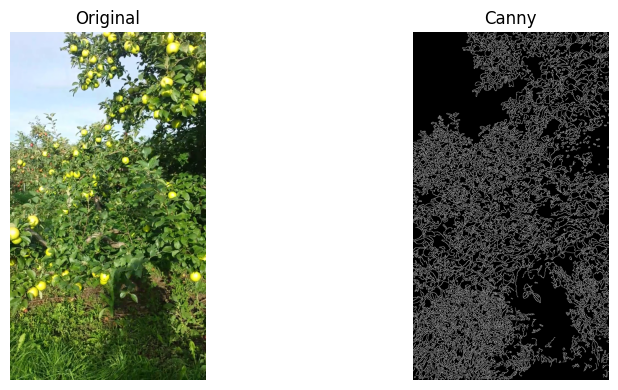

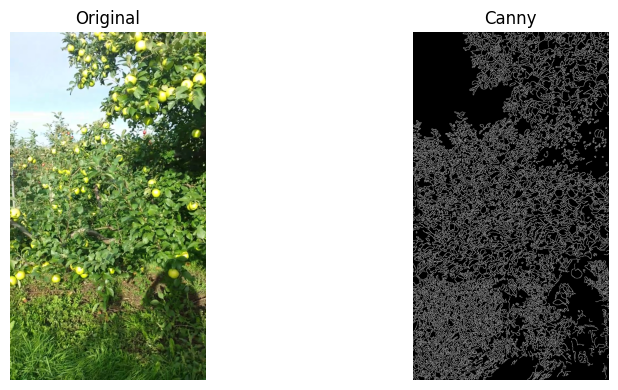

Hough círculos: 1/70
Hough círculos: 10/70
Hough círculos: 20/70
Hough círculos: 30/70
Hough círculos: 40/70
Hough círculos: 50/70
Hough círculos: 60/70
Hough círculos: 70/70
                  iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                     
Hough círculos  0.047  0.089      0.047     1.0     0.0            0.0         0.0         -58.7       58.7


In [11]:
def bordes_canny(img, bajo=50, alto=150, sigma=1.5):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    gris = cv.GaussianBlur(gris, (5, 5), sigma)
    return cv.Canny(gris, bajo, alto)

def hough_circulos_manzanas(
    img,
    dp=1.2,
    min_dist=25,
    param1=100,
    param2=25,
    min_radius=8,
    max_radius=80
):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    gris = cv.GaussianBlur(gris, (5, 5), 1.5)

    circulos = cv.HoughCircles(
        gris,
        cv.HOUGH_GRADIENT,
        dp=dp,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )

    mascara = np.zeros(gris.shape, dtype=np.uint8)

    if circulos is None:
        return mascara

    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    color = cv.inRange(hsv, (22, 50, 50), (45, 255, 255))

    for x, y, r in np.round(circulos[0]).astype(int):
        region = np.zeros_like(mascara)
        cv.circle(region, (x, y), r, 255, -1)

        if np.any(region):
            cobertura = np.mean(color[region > 0] > 0)
            if cobertura >= 0.20:
                mascara[region > 0] = 255

    return mascara

CATALOGO["hough_circulos"] = hough_circulos_manzanas

# Visualización de Canny sobre dos ejemplos.
for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)
    edges = bordes_canny(img)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[1].imshow(edges, cmap="gray")
    ax[1].set_title("Canny")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

metodo_hough = Metodo(
    "Hough círculos",
    seg=("hough_circulos", {}),
    post=[
        ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 5}),
        ("filtrar_area", {"area_min": 40})
    ]
)

tabla_hough = comparar([metodo_hough], ajuste)
print(resumen(tabla_hough).round(3).to_string())

## 9. Watershed

Watershed se aplica sobre la máscara obtenida por color para intentar separar manzanas que aparecen conectadas.

In [12]:
def watershed_dist(mascara, img, frac=0.7):
    m = (mascara > 0).astype(np.uint8)

    dist = cv.distanceTransform(m, cv.DIST_L2, 5)
    n, etiquetas = cv.connectedComponents(m, connectivity=8)

    semillas = np.zeros_like(m)

    for i in range(1, n):
        region = etiquetas == i
        max_dist = dist[region].max()

        if max_dist > 0:
            semillas[
                region & (dist >= frac * max_dist)
            ] = 1

    if semillas.sum() == 0:
        return m * 255

    _, marcadores = cv.connectedComponents(semillas)
    marcadores = marcadores.astype(np.int32) + 1

    marcadores[m == 0] = 1
    marcadores[(m == 1) & (semillas == 0)] = 0

    marcadores = cv.watershed(img.copy(), marcadores)

    return (marcadores >= 2).astype(np.uint8) * 255

CATALOGO["watershed_dist"] = watershed_dist

post_watershed = [
    ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 11}),
    ("rellenar_huecos", {}),
    ("dilatar", {"k": 5}),
]

metodos_watershed = []

for frac in [0.5, 0.7, 0.9]:
    metodos_watershed.append(
        Metodo(
            f"Watershed frac={frac}",
            preproc=[("mediana", {"k": 5})],
            seg=("umbral_b", {"lo": 185}),
            post=post_watershed + [
                ("watershed_dist", {"frac": frac}),
                ("filtrar_area", {"area_min": 100})
            ]
        )
    )

tabla_watershed = comparar(metodos_watershed, ajuste)
print(resumen(tabla_watershed).round(3).to_string())

Watershed frac=0.5: 1/70
Watershed frac=0.5: 10/70
Watershed frac=0.5: 20/70
Watershed frac=0.5: 30/70
Watershed frac=0.5: 40/70
Watershed frac=0.5: 50/70
Watershed frac=0.5: 60/70
Watershed frac=0.5: 70/70
Watershed frac=0.7: 1/70
Watershed frac=0.7: 10/70
Watershed frac=0.7: 20/70
Watershed frac=0.7: 30/70
Watershed frac=0.7: 40/70
Watershed frac=0.7: 50/70
Watershed frac=0.7: 60/70
Watershed frac=0.7: 70/70
Watershed frac=0.9: 1/70
Watershed frac=0.9: 10/70
Watershed frac=0.9: 20/70
Watershed frac=0.9: 30/70
Watershed frac=0.9: 40/70
Watershed frac=0.9: 50/70
Watershed frac=0.9: 60/70
Watershed frac=0.9: 70/70
                      iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                         
Watershed frac=0.5  0.345  0.469      0.624   0.394   0.292          0.316       0.277        -0.329     17.157
Watershed frac=0.7  0.314  0.439      0.643

## 10. LBP y HOG

LBP se analiza como descriptor de textura y HOG como descriptor basado en gradientes y forma.

En este proyecto se estudian como características complementarias; no se fuerza su incorporación a la segmentación si no mejoran el resultado.

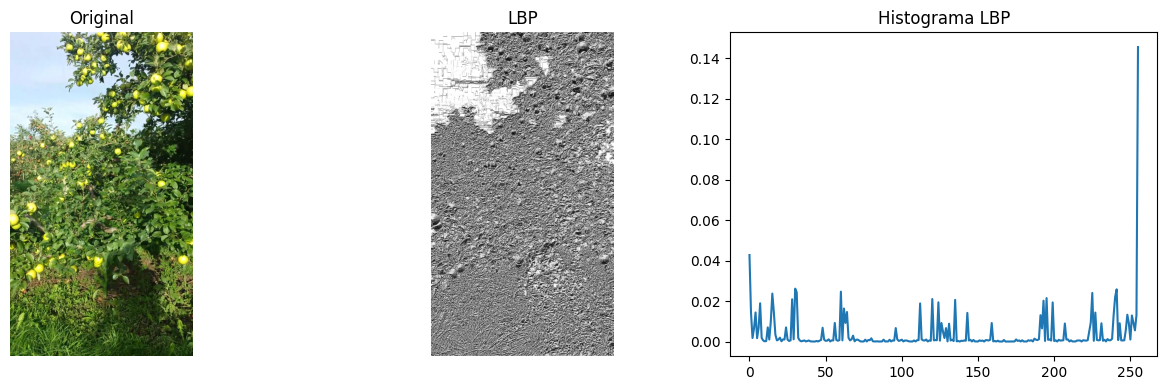

img_042.png -> longitud HOG: 1764


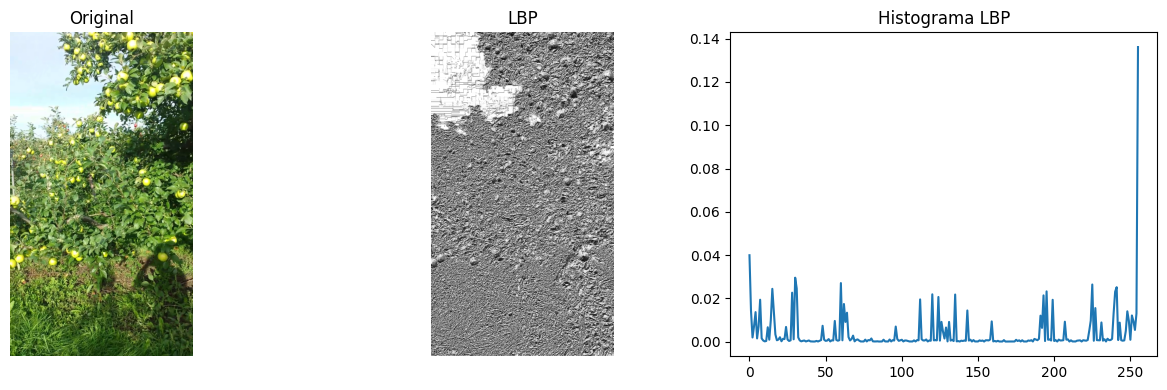

img_041.png -> longitud HOG: 1764


In [13]:
def lbp_imagen(gris, radius=1, points=8):
    gris = gris.astype(np.float32)
    h, w = gris.shape
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)

    lbp = np.zeros((h, w), dtype=np.uint8)

    for p in range(points):
        angulo = 2 * np.pi * p / points
        dx = radius * np.cos(angulo)
        dy = -radius * np.sin(angulo)

        vecino = cv.remap(
            gris,
            xx + dx,
            yy + dy,
            interpolation=cv.INTER_LINEAR,
            borderMode=cv.BORDER_REFLECT
        )

        lbp |= (
            (vecino >= gris).astype(np.uint8) << p
        )

    hist = np.bincount(
        lbp.ravel(),
        minlength=2 ** points
    ).astype(np.float64)

    hist /= hist.sum() if hist.sum() else 1.0

    return lbp, hist

hog = cv.HOGDescriptor(
    (64, 64),
    (16, 16),
    (8, 8),
    (8, 8),
    9
)

def hog_region(img, mascara=None, size=(64, 64)):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    if mascara is not None:
        gris = cv.bitwise_and(
            gris,
            gris,
            mask=(mascara > 0).astype(np.uint8) * 255
        )

    gris = cv.resize(gris, size)
    return hog.compute(gris).ravel()

for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)

    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    lbp, hist = lbp_imagen(gris)
    descriptor = hog_region(img, gt)

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[1].imshow(lbp, cmap="gray")
    ax[1].set_title("LBP")
    ax[2].plot(hist)
    ax[2].set_title("Histograma LBP")
    for a in ax:
        a.axis("off") if a is not ax[2] else None
    plt.tight_layout()
    plt.show()

    print(nombre, "-> longitud HOG:", len(descriptor))

## 11. Comparación final en ajuste

Aquí se reúnen las familias de métodos ya estudiadas. La elección final se hace exclusivamente con el conjunto de ajuste.

El criterio principal es Dice/IoU de píxel, complementado con F1 de objeto y error de conteo.

In [14]:
post_final = [
    ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 11}),
    ("rellenar_huecos", {}),
    ("filtrar_area", {"area_min": 100})
]

candidatos = [
    Metodo(
        "HSV base",
        seg=("umbral_hsv", {})
    ),

    Metodo(
        "Lab b",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_final
    ),

    Metodo(
        "Lab b + L",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_bL", {"b_lo": 185, "L_lo": 0}),
        post=post_final
    ),

    Metodo(
        "Adaptativo b",
        preproc=[("mediana", {"k": 5})],
        seg=("adaptativo_b", {"bloque": 51, "c": 10, "minimo": 150}),
        post=post_final
    ),

    Metodo(
        "Otsu b",
        preproc=[("mediana", {"k": 5})],
        seg=("otsu_b", {}),
        post=post_final
    ),

    Metodo(
        "Otsu gris",
        preproc=[("mediana", {"k": 5})],
        seg=("otsu_gris", {}),
        post=post_final
    ),

    Metodo(
        "GMM k=3",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 3}),
        post=post_final
    ),

    Metodo(
        "GMM k=4",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 4}),
        post=post_final
    ),

    Metodo(
        "GMM k=6",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 6}),
        post=post_final
    ),

    Metodo(
        "Hough círculos",
        seg=("hough_circulos", {}),
        post=[
            ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 5}),
            ("filtrar_area", {"area_min": 40})
        ]
    ),

    Metodo(
        "Watershed 0.5",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_watershed + [
            ("watershed_dist", {"frac": 0.5}),
            ("filtrar_area", {"area_min": 100})
        ]
    ),

    Metodo(
        "Watershed 0.7",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_watershed + [
            ("watershed_dist", {"frac": 0.7}),
            ("filtrar_area", {"area_min": 100})
        ]
    ),

    Metodo(
        "Watershed 0.9",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_watershed + [
            ("watershed_dist", {"frac": 0.9}),
            ("filtrar_area", {"area_min": 100})
        ]
    ),

    Metodo(
        "b + dilatación 5",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_final + [("dilatar", {"k": 5})]
    ),

    Metodo(
        "b + dilatación 9",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_final + [("dilatar", {"k": 9})]
    ),

    Metodo(
        "Histéresis 185/180",
        preproc=[("mediana", {"k": 5})],
        seg=("histeresis_b", {"alto": 185, "bajo": 180}),
        post=post_final
    ),

    Metodo(
        "Histéresis 185/175",
        preproc=[("mediana", {"k": 5})],
        seg=("histeresis_b", {"alto": 185, "bajo": 175}),
        post=post_final
    ),
]

tabla_ajuste = comparar(candidatos, ajuste)
resumen_ajuste = resumen(tabla_ajuste)

print(resumen_ajuste.round(3).to_string())

HSV base: 1/70
HSV base: 10/70
HSV base: 20/70
HSV base: 30/70
HSV base: 40/70
HSV base: 50/70
HSV base: 60/70
HSV base: 70/70
Lab b: 1/70
Lab b: 10/70
Lab b: 20/70
Lab b: 30/70
Lab b: 40/70
Lab b: 50/70
Lab b: 60/70
Lab b: 70/70
Lab b + L: 1/70
Lab b + L: 10/70
Lab b + L: 20/70
Lab b + L: 30/70
Lab b + L: 40/70
Lab b + L: 50/70
Lab b + L: 60/70
Lab b + L: 70/70
Adaptativo b: 1/70
Adaptativo b: 10/70
Adaptativo b: 20/70
Adaptativo b: 30/70
Adaptativo b: 40/70
Adaptativo b: 50/70
Adaptativo b: 60/70
Adaptativo b: 70/70
Otsu b: 1/70
Otsu b: 10/70
Otsu b: 20/70
Otsu b: 30/70
Otsu b: 40/70
Otsu b: 50/70
Otsu b: 60/70
Otsu b: 70/70
Otsu gris: 1/70
Otsu gris: 10/70
Otsu gris: 20/70
Otsu gris: 30/70
Otsu gris: 40/70
Otsu gris: 50/70
Otsu gris: 60/70
Otsu gris: 70/70
GMM k=3: 1/70
GMM k=3: 10/70
GMM k=3: 20/70
GMM k=3: 30/70
GMM k=3: 40/70
GMM k=3: 50/70
GMM k=3: 60/70
GMM k=3: 70/70
GMM k=4: 1/70
GMM k=4: 10/70
GMM k=4: 20/70
GMM k=4: 30/70
GMM k=4: 40/70
GMM k=4: 50/70
GMM k=4: 60/70
GMM k=4

## 12. Selección de los métodos finales

Se seleccionan los mejores resultados del conjunto de ajuste.

- **Mejor Dice:** mejor calidad global de segmentación a nivel de píxel.
- **Mejor F1 de objeto:** mejor detección de objetos considerando su correspondencia con la referencia.

Si ambos criterios seleccionan el mismo método, solo se evaluará una vez en test.

In [15]:
mejor_dice = resumen_ajuste["dice"].idxmax()
mejor_objeto = resumen_ajuste["obj_f1"].idxmax()

seleccionados = list(dict.fromkeys([
    mejor_dice,
    mejor_objeto
]))

metodos_finales = [
    metodo for metodo in candidatos
    if metodo.nombre in seleccionados
]

print("Mejor por Dice:", mejor_dice)
print("Mejor por F1 de objeto:", mejor_objeto)
print("Métodos que pasan a test:", seleccionados)

Mejor por Dice: b + dilatación 5
Mejor por F1 de objeto: b + dilatación 5
Métodos que pasan a test: ['b + dilatación 5']


## 13. Evaluación final en test

El conjunto de test no se utiliza para modificar parámetros ni elegir métodos. Solo se usa para obtener la evaluación final.

In [16]:
tabla_test = comparar(metodos_finales, test)

resumen_test = resumen(tabla_test)

print("RESULTADOS FINALES EN TEST")
print(resumen_test.round(3).to_string())

b + dilatación 5: 1/30
b + dilatación 5: 10/30
b + dilatación 5: 20/30
b + dilatación 5: 30/30
RESULTADOS FINALES EN TEST
                    iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                       
b + dilatación 5  0.309  0.411      0.411   0.454   0.259          0.293       0.243        -0.933     20.867


In [17]:
tabla_final_memoria = (
    tabla_test.groupby("metodo")[
        [
            "iou", "dice", "precision", "recall",
            "obj_precision", "obj_recall", "obj_f1",
            "n_gt", "n_pred", "error_abs"
        ]
    ]
    .mean()
    .round(3)
)

tabla_final_memoria

,iou,dice,precision,recall,obj_precision,obj_recall,obj_f1,n_gt,n_pred,error_abs
metodo,,,,,,,,,,
b + dilatación 5,0.309,0.411,0.411,0.454,0.293,0.243,0.259,52.767,51.833,20.867


## 14. Visualización de resultados finales

Se muestran algunos ejemplos del conjunto de test junto con la referencia y las predicciones finales.

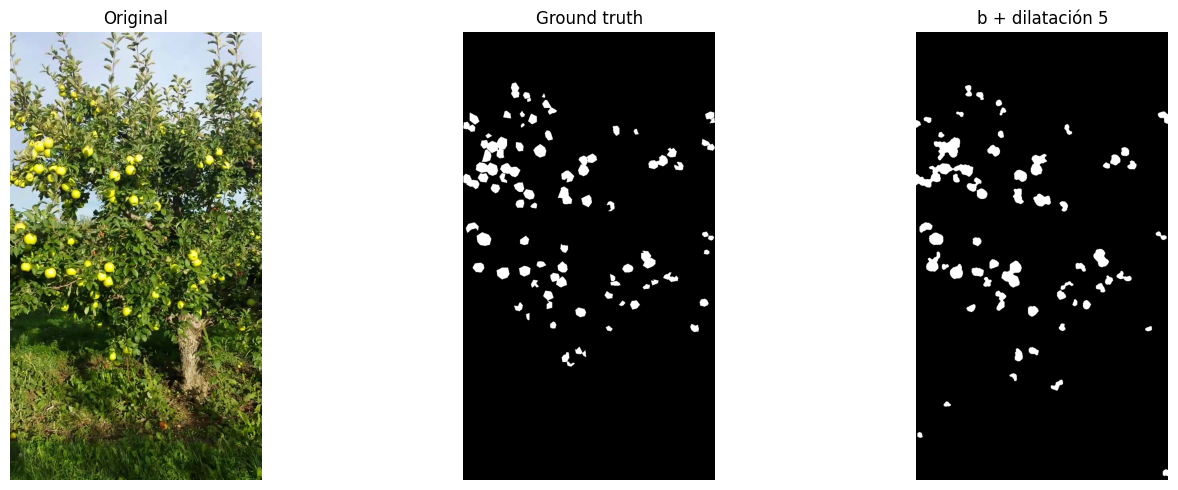

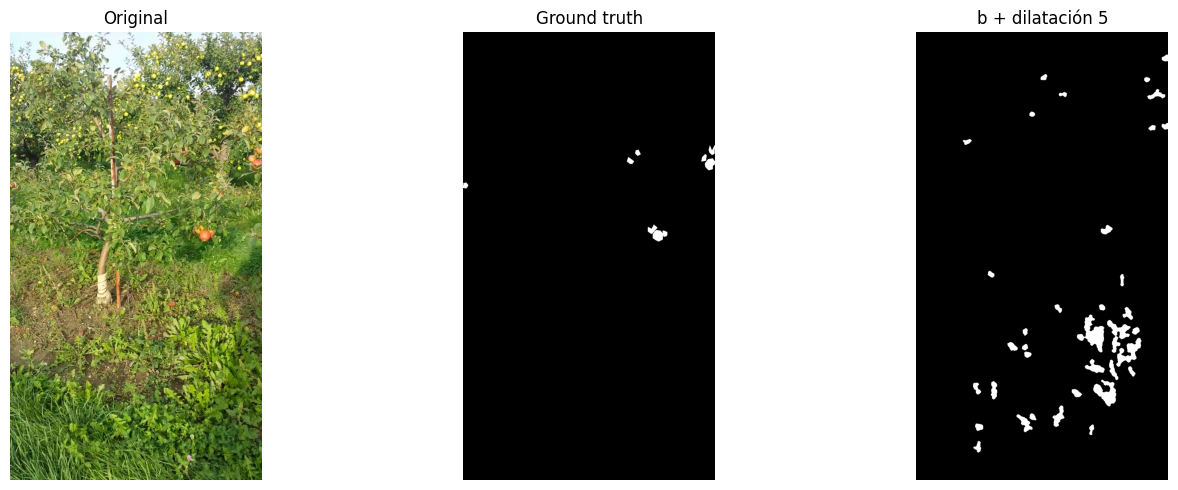

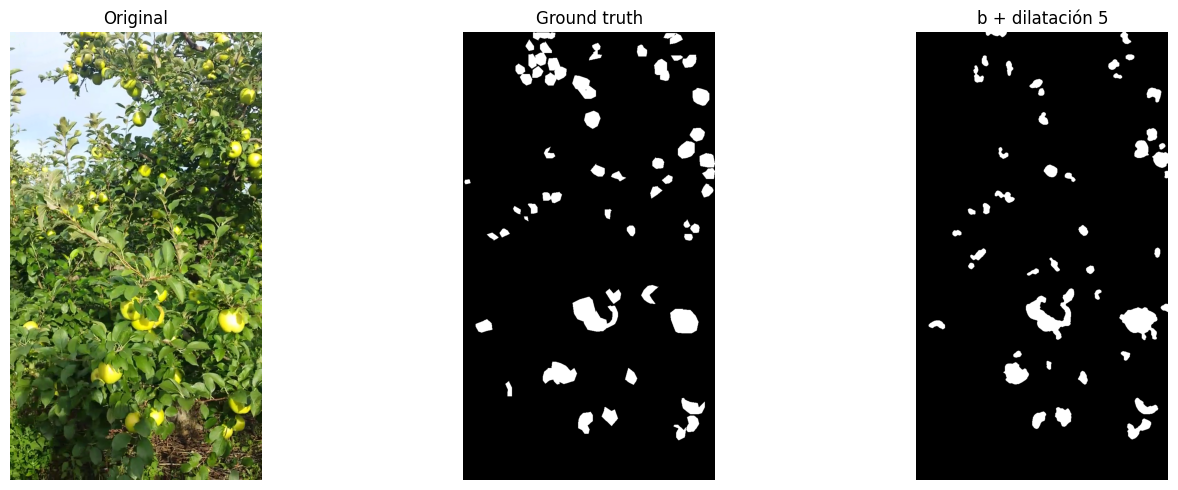

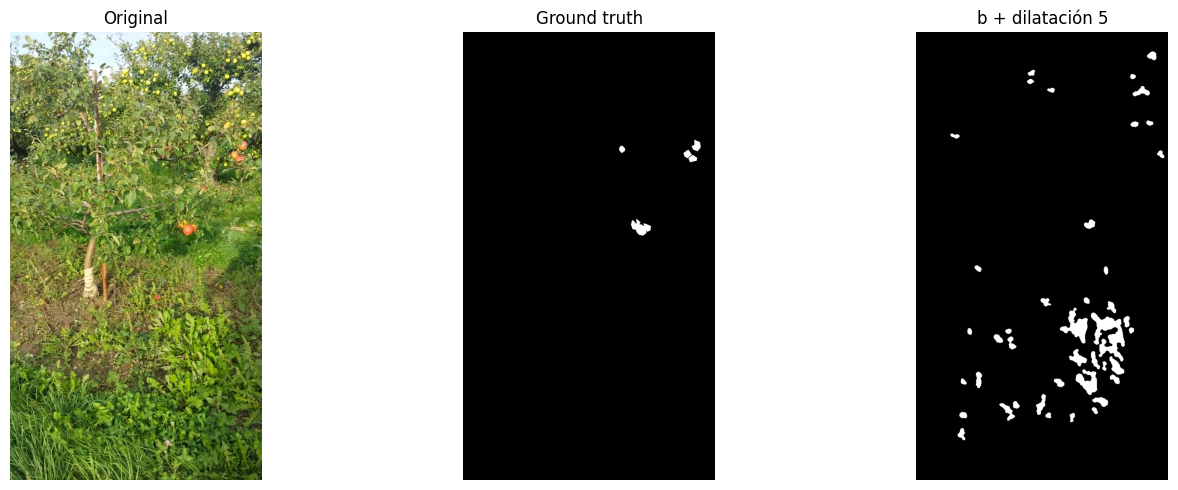

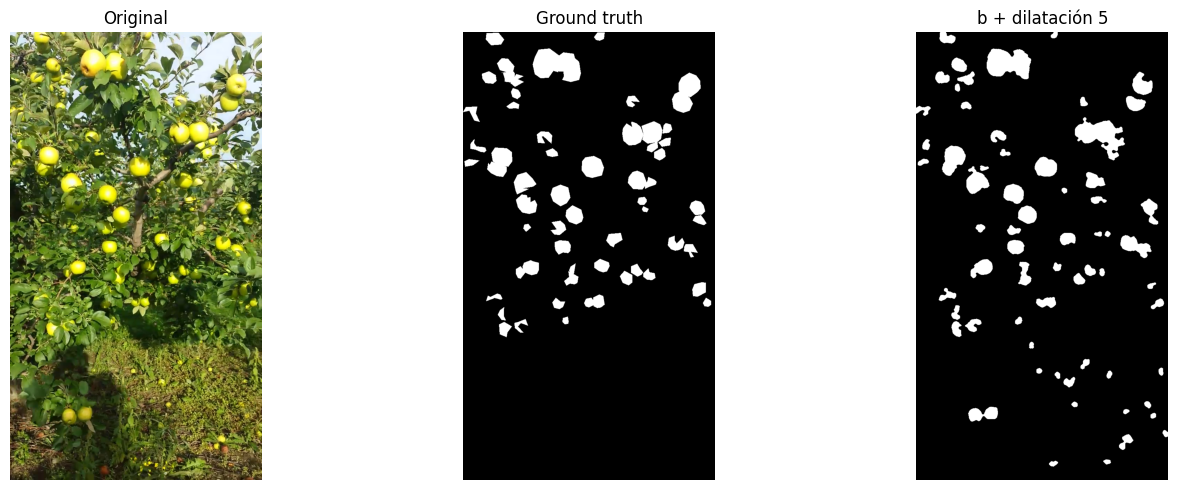

In [18]:
for nombre in test[:5]:
    img, gt = cargar_par(nombre)

    fig, ax = plt.subplots(
        1,
        2 + len(metodos_finales),
        figsize=(5 * (2 + len(metodos_finales)), 5)
    )

    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(gt, cmap="gray")
    ax[1].set_title("Ground truth")
    ax[1].axis("off")

    for j, metodo in enumerate(metodos_finales, start=2):
        pred = metodo(img)
        ax[j].imshow(pred, cmap="gray")
        ax[j].set_title(metodo.nombre)
        ax[j].axis("off")

    plt.tight_layout()
    plt.show()

## 15. Conclusiones

Al finalizar la ejecución, la memoria debe recoger:

1. Qué información aportó el análisis de color.
2. Qué métodos de segmentación se probaron.
3. Qué técnicas mejoraron o empeoraron el resultado.
4. Qué método obtuvo el mejor Dice/IoU.
5. Qué método obtuvo el mejor F1 de objeto.
6. El resultado final sobre test.
7. Una comparación visual entre predicción y ground truth.

No se deben inventar resultados: las conclusiones se redactan a partir de las tablas obtenidas al ejecutar el notebook.
